<a href="https://colab.research.google.com/github/tejasimha02/Number-Gussing-Game/blob/main/email_spam_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import pandas as pd
import numpy as np
import re
import zipfile

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
uploaded = files.upload()

zip_name = next(iter(uploaded))

with zipfile.ZipFile(zip_name, 'r') as z:
    csv_files = [
        name for name in z.namelist()
        if name.lower().endswith('.csv')
    ]

    print("CSV files found:", csv_files)

    if not csv_files:
        raise FileNotFoundError("No CSV file found in ZIP!")

    with z.open(csv_files[0]) as f:
        df = pd.read_csv(f, encoding='latin-1')

print("Dataset loaded successfully!")

print(df.head())

Saving enron_spam_data.zip to enron_spam_data.zip
CSV files found: ['enron_spam_data.csv']
Dataset loaded successfully!
   Message ID                       Subject  \
0           0  christmas tree farm pictures   
1           1      vastar resources , inc .   
2           2  calpine daily gas nomination   
3           3                    re : issue   
4           4     meter 7268 nov allocation   

                                             Message Spam/Ham        Date  
0                                                NaN      ham  1999-12-10  
1  gary , production from the high island larger ...      ham  1999-12-13  
2             - calpine daily gas nomination 1 . doc      ham  1999-12-14  
3  fyi - see note below - already done .\nstella\...      ham  1999-12-14  
4  fyi .\n- - - - - - - - - - - - - - - - - - - -...      ham  1999-12-14  


In [7]:
df.columns = df.columns.str.strip()

def clean_text(text):

    text = str(text)

    text = text.lower()

    text = re.sub(r'<[^>]+>', ' ', text)

    text = re.sub(
        r'https?://\S+|www\.\S+',
        ' URL ',
        text
    )

    text = re.sub(
        r'\S+@\S+',
        ' EMAIL ',
        text
    )

    text = re.sub(
        r'[^a-zA-Z\s]',
        ' ',
        text
    )

    text = re.sub(r'\s+', ' ', text).strip()

    return text


df["combined_text"] = (
    df["Subject"].fillna("").astype(str)
    + " "
    + df["Message"].fillna("").astype(str)
)

df["label_clean"] = (
    df["Spam/Ham"].astype(str).str.lower().str.strip()
)

df = df[
    df["label_clean"].isin(["spam", "ham"])
].copy()

df["clean_text"] = df["combined_text"].apply(clean_text)

df["target"] = df["label_clean"].map({
    "ham": 0,
    "spam": 1
})

df = df[df["clean_text"].str.len() > 0]

print("Data preprocessing completed!")
print(df[["clean_text", "label_clean"]].head())

Data preprocessing completed!
                                          clean_text label_clean
0                       christmas tree farm pictures         ham
1  vastar resources inc gary production from the ...         ham
2  calpine daily gas nomination calpine daily gas...         ham
3  re issue fyi see note below already done stell...         ham
4  meter nov allocation fyi forwarded by lauri a ...         ham


In [8]:
X = df["clean_text"]

y = df["target"]

print("Text data prepared!")
print("Total emails:", len(X))

Text data prepared!
Total emails: 33662


In [9]:
from sklearn.model_selection import train_test_split

print("Library imported successfully!")

Library imported successfully!


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training emails:", len(X_train))
print("Testing emails:", len(X_test))

Training emails: 26929
Testing emails: 6733


In [11]:
model = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=30000,
        ngram_range=(1, 2),
        min_df=2,
        stop_words='english'
    )),

    ('classifier', MultinomialNB(alpha=0.5))
])

model.fit(X_train, y_train)

print("Machine Learning model trained successfully!")

Machine Learning model trained successfully!


In [12]:
y_pred = model.predict(X_test)

print("Accuracy:",
      accuracy_score(y_test, y_pred))

print("Precision:",
      precision_score(y_test, y_pred, zero_division=0))

print("Recall:",
      recall_score(y_test, y_pred, zero_division=0))

print("F1 Score:",
      f1_score(y_test, y_pred, zero_division=0))

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred,
    target_names=["Ham", "Spam"],
    zero_division=0
))

Accuracy: 0.9894549235110649
Precision: 0.9880640465793304
Recall: 0.9912383177570093
F1 Score: 0.9896486368275259

Classification Report:
              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99      3309
        Spam       0.99      0.99      0.99      3424

    accuracy                           0.99      6733
   macro avg       0.99      0.99      0.99      6733
weighted avg       0.99      0.99      0.99      6733



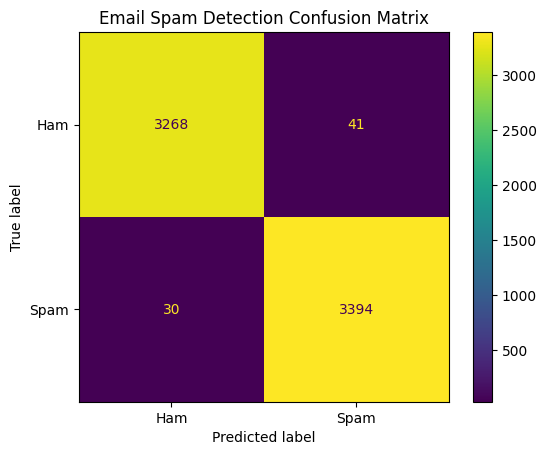

In [13]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=["Ham", "Spam"]
)

plt.title("Email Spam Detection Confusion Matrix")

plt.show()

In [14]:
def predict_email(email_text):

    cleaned = clean_text(email_text)

    prediction = model.predict([cleaned])[0]

    if prediction == 1:
        return "SPAM EMAIL"

    else:
        return "NOT SPAM EMAIL"


email1 = """
Congratulations! You won a free prize.
Click here to claim your reward now.
"""

email2 = """
Hello, your project meeting is scheduled
for tomorrow at 10 AM.
"""

print("Email 1:", predict_email(email1))

print("Email 2:", predict_email(email2))

Email 1: SPAM EMAIL
Email 2: NOT SPAM EMAIL


In [15]:
import joblib

joblib.dump(model, "email_spam_model.joblib")

print("Model saved successfully!")

Model saved successfully!
